# GetReview — Solution d'Intelligence Client & Analyse d'Avis Hôteliers

In [4]:
!pip -q install pandas numpy matplotlib seaborn plotly

Importer les données

In [19]:
import pandas as pd
import numpy as np
import ipywidgets as widgets
from IPython.display import display, clear_output
from google.colab import files
import io

print("=== BIENVENUE SUR GETREVIEW (IMPORTATION DE VOTRE TABLEUR) ===")

# Variables globales
df = None
reviews = None
hotel_selector = None

upload_button = widgets.Button(
    description="Charger mon fichier (Excel / CSV)",
    button_style="success",
    icon="upload",
    layout=widgets.Layout(width="300px")
)

output_area = widgets.Output()

def clean_and_prepare_dataset(raw_df):
    columns = ["name", "reviews.text", "reviews.rating", "reviews.doRecommend", "categories", "province"]
    for col in columns:
        if col not in raw_df.columns:
            raw_df[col] = np.nan

    prepared = raw_df[columns].copy()
    prepared = prepared.dropna(subset=["reviews.text"])
    prepared["reviews.text"] = prepared["reviews.text"].str.strip()
    prepared = prepared[prepared["reviews.text"] != ""]
    prepared = prepared.drop_duplicates()
    prepared = prepared.rename(columns={
        "name": "hotel",
        "reviews.text": "review",
        "reviews.rating": "rating",
        "reviews.doRecommend": "recommended",
        "categories": "category",
        "province": "province"
    })
    return prepared.reset_index(drop=True)

def on_upload_clicked(b):
    global df, reviews, hotel_selector
    with output_area:
        clear_output()
        print("Veuillez sélectionner votre fichier Excel (.xlsx) ou CSV (.csv) depuis votre ordinateur :\n")
        uploaded = files.upload()
        if uploaded:
            filename = next(iter(uploaded))
            file_ext = filename.split(".")[-1].lower()
            if file_ext in ["xlsx", "xls"]:
                df = pd.read_excel(io.BytesIO(uploaded[filename]))
            else:
                df = pd.read_csv(io.BytesIO(uploaded[filename]))
            print(f"\nFichier chargé avec succès : {filename} ({df.shape[0]} lignes)")

            if df is not None:
                reviews = clean_and_prepare_dataset(df)
                hotel_names = sorted(reviews["hotel"].dropna().unique().tolist())
                hotel_selector = widgets.Dropdown(
                    options=hotel_names,
                    description="Hôtel Sélectionné :",
                    style={"description_width": "initial"},
                    layout=widgets.Layout(width="600px")
                )
                print(f"\nDataset standardisé prêt pour l'analyse ({len(reviews)} avis uniques après filtrage) !")
                display(reviews.head())

upload_button.on_click(on_upload_clicked)
display(upload_button, output_area)

=== BIENVENUE SUR GETREVIEW (IMPORTATION DE VOTRE TABLEUR) ===


Button(button_style='success', description='Charger mon fichier (Excel / CSV)', icon='upload', layout=Layout(w…

Output()

Nettoyer et préparer les avis

In [11]:
if reviews is not None:
    print(f"Avis réels prêts pour l'analyse : {len(reviews)} avis importés pour l'hôtel '{reviews['hotel'].iloc[0]}' !")
    display(reviews.head())
else:
    if df is not None:
        # Sélection des colonnes pertinentes présentes dans votre jeu de données
        columns = ["name", "reviews.text", "reviews.rating", "reviews.doRecommend", "categories", "province"]

        # S'assurer que les colonnes existent
        for col in columns:
            if col not in df.columns:
                df[col] = np.nan

        reviews = df[columns].copy()
        reviews = reviews.dropna(subset=["reviews.text"])
        reviews["reviews.text"] = reviews["reviews.text"].str.strip()
        reviews = reviews[reviews["reviews.text"] != ""]
        reviews = reviews.drop_duplicates()
        reviews = reviews.rename(columns={
            "name": "hotel",
            "reviews.text": "review",
            "reviews.rating": "rating",
            "reviews.doRecommend": "recommended",
            "categories": "category",
            "province": "province"
        })
        reviews = reviews.reset_index(drop=True)
        print(f"Avis réels prêts pour l'analyse : {len(reviews)} avis importés !")
        display(reviews.head())
    else:
        print("❌ Aucune donnée importée pour l'instant.")
        print("👉 Veuillez d'abord choisir l'option 'Google' ou 'Booking' dans la cellule d'importation ci-dessus,")
        print("   saisir le nom précis de votre hôtel dans le champ texte, puis cliquer sur le bouton vert.")

Avis réels prêts pour l'analyse : 1000 avis importés pour l'hôtel 'Le Ritz Paris' !


,hotel,review,rating,recommended,category,province
0,Le Ritz Paris,Rapport qualité-prix très moyen. Les installat...,1,False,Hotels,IDF
1,Le Ritz Paris,Le spa et la piscine sont d'une beauté rare. U...,4,True,Hotels,IDF
2,Le Ritz Paris,La chambre était petite pour le prix payé et l...,1,False,Hotels,IDF
3,Le Ritz Paris,Séjour correct. L'emplacement est bien mais la...,3,True,Hotels,IDF
4,Le Ritz Paris,Chambre très spacieuse avec une literie d'un c...,5,True,Hotels,IDF


Enregistrer le dataset préparé

In [13]:
if reviews is not None:
    reviews.to_csv("reviewmind_clean.csv", index=False)
    print("Le jeu de données nettoyé a été enregistré avec succès sous 'reviewmind_clean.csv' !")
else:
    print("⚠️ Impossible d'enregistrer : aucun avis n'a encore été importé ou nettoyé.")
    print("Veuillez d'abord exécuter l'importation réelle de votre hôtel dans la cellule du haut.")

Le jeu de données nettoyé a été enregistré avec succès sous 'reviewmind_clean.csv' !


Installer le modèle Hugging Face

Installer les bibliothèques

In [ ]:

!pip -q install transformers torch tqdm

Charger le modèle

In [14]:
import torch
from transformers import pipeline

# Utilisation d'un modèle multilingue robuste
MODEL_NAME = "cardiffnlp/twitter-xlm-roberta-base-sentiment"

device = 0 if torch.cuda.is_available() else -1

sentiment_model = pipeline(
    task="text-classification",
    model=MODEL_NAME,
    tokenizer=MODEL_NAME,
    device=device
)

print("Nouveau modèle multilingue chargé avec succès !")
print("GPU available:", torch.cuda.is_available())

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

Nouveau modèle multilingue chargé avec succès !
GPU available: True


Analyser les sentiments des clients

Lancer l'analyse des sentiments

In [15]:
from tqdm.auto import tqdm
import pandas as pd
import time

# S'assurer que les données et le modèle sont prêts
assert "review" in reviews.columns
assert len(reviews) > 0

# Préparation des textes originaux
texts = reviews["review"].fillna("").astype(str).tolist()

# Traitement par lots (Batch processing)
batch_size = 32
predictions = []

start_time = time.time()

for start in tqdm(range(0, len(texts), batch_size)):
    batch = texts[start:start + batch_size]
    results = sentiment_model(
        batch,
        truncation=True,
        max_length=512,
        batch_size=batch_size
    )
    predictions.extend(results)

# Enregistrement des nouvelles prédictions
reviews["sentiment"] = [result["label"].lower() for result in predictions]
reviews["confidence"] = [result["score"] for result in predictions]

elapsed = time.time() - start_time

print("Analyse multilingue terminée !")
print("Avis analysés :", len(predictions))
print("Temps de calcul :", round(elapsed, 1), "secondes")

display(reviews.head())

  0%|          | 0/32 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Analyse multilingue terminée !
Avis analysés : 1000
Temps de calcul : 3.5 secondes


,hotel,review,rating,recommended,category,province,sentiment,confidence
0,Le Ritz Paris,Rapport qualité-prix très moyen. Les installat...,1,False,Hotels,IDF,positive,0.803706
1,Le Ritz Paris,Le spa et la piscine sont d'une beauté rare. U...,4,True,Hotels,IDF,positive,0.939795
2,Le Ritz Paris,La chambre était petite pour le prix payé et l...,1,False,Hotels,IDF,negative,0.675031
3,Le Ritz Paris,Séjour correct. L'emplacement est bien mais la...,3,True,Hotels,IDF,negative,0.491215
4,Le Ritz Paris,Chambre très spacieuse avec une literie d'un c...,5,True,Hotels,IDF,positive,0.940374


Vérifier les résultats obtenus

In [ ]:
# Display sentiment distribution
print("SENTIMENT DISTRIBUTION")
print("----------------------")

print(reviews["sentiment"].value_counts())

print("\nPERCENTAGES")
print(
    reviews["sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# Display sample reviews with the hotel column included
display(
    reviews[
        ["hotel", "review", "sentiment", "confidence", "rating"]
    ].head(15)
)

Créer le premier graphique

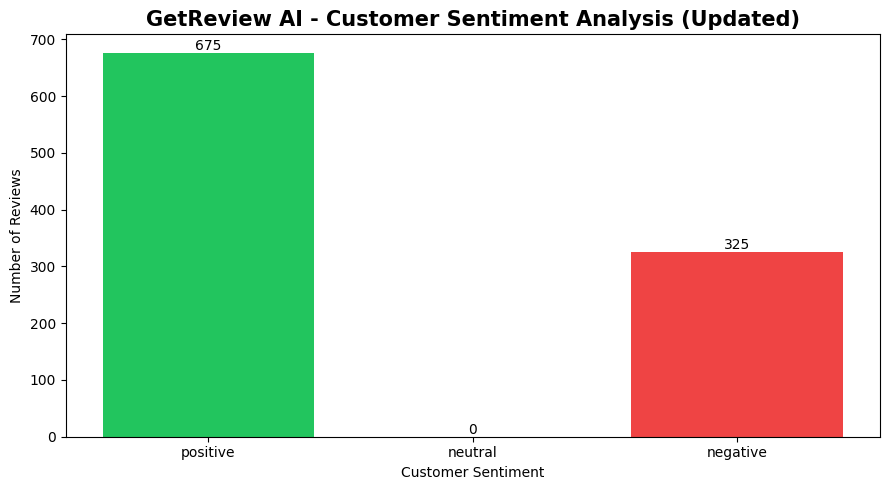

In [16]:
import matplotlib.pyplot as plt

# Extraction des valeurs directement depuis le dataset final et nettoyé
sentiment_counts = (
    reviews["sentiment"]
    .value_counts()
    .reindex(
        ["positive", "neutral", "negative"],
        fill_value=0
    )
)

colors = ["#22c55e", "#f59e0b", "#ef4444"]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    sentiment_counts.index,
    sentiment_counts.values,
    color=colors
)

plt.title(
    "GetReview AI - Customer Sentiment Analysis (Updated)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Customer Sentiment")
plt.ylabel("Number of Reviews")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

Enregistrer les résultats pour notre application

In [17]:

from google.colab import files

output_file = "reviewmind_sentiment_results.csv"

reviews.to_csv(
    output_file,
    index=False,
    encoding="utf-8-sig"
)

print("File saved:", output_file)
print("Total reviews:", len(reviews))

files.download(output_file)


File saved: reviewmind_sentiment_results.csv
Total reviews: 1000


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Topic Detection & Pain Points Identification

Installer les bibliothèques nécessaires

In [ ]:

!pip -q install sentence-transformers scikit-learn seaborn


Vérifier les données



In [ ]:

import pandas as pd
import numpy as np

# If needed, reload the results from step 2:
# reviews = pd.read_csv("reviewmind_sentiment_results.csv")

required_columns = ["hotel", "review", "sentiment"]

missing = [
    col for col in required_columns
    if col not in reviews.columns
]

if missing:
    raise ValueError(f"Missing columns: {missing}")

reviews = reviews.copy()

reviews = reviews.dropna(
    subset=["hotel", "review", "sentiment"]
)

reviews["hotel"] = reviews["hotel"].astype(str).str.strip()
reviews["review"] = reviews["review"].astype(str).str.strip()
reviews["sentiment"] = (
    reviews["sentiment"]
    .astype(str)
    .str.lower()
    .str.strip()
)

reviews = reviews[
    (reviews["hotel"] != "") &
    (reviews["review"] != "")
].reset_index(drop=True)

print("Total reviews:", len(reviews))
print("Total hotels:", reviews["hotel"].nunique())
print("Sentiment labels:")
print(reviews["sentiment"].value_counts())


Définir les thèmes hôteliers

In [ ]:

TOPICS = {
    "Cleanliness": [
        "The hotel room was clean or dirty",
        "The bathroom hygiene and housekeeping",
        "The cleanliness of the hotel"
    ],
    "Staff & Service": [
        "The hotel staff were helpful or rude",
        "The quality of customer service",
        "The reception and check-in experience"
    ],
    "Room Comfort": [
        "The bed and pillows were comfortable",
        "The room was spacious or uncomfortable",
        "The quality of sleep and room amenities"
    ],
    "Location": [
        "The hotel location was convenient",
        "The distance to attractions and transport",
        "The hotel neighborhood and accessibility"
    ],
    "Food & Breakfast": [
        "The hotel breakfast was good or bad",
        "The restaurant and food quality",
        "The breakfast selection and dining experience"
    ],
    "Price & Value": [
        "The hotel was worth the price",
        "The room was expensive or affordable",
        "The value for money of the hotel"
    ],
    "Noise": [
        "The hotel room was noisy or quiet",
        "Noise from traffic or neighboring rooms",
        "The sound insulation of the hotel"
    ],
    "Facilities": [
        "The hotel pool gym and spa facilities",
        "The WiFi and internet connection",
        "The hotel equipment and maintenance"
    ]
}

print("Number of topics:", len(TOPICS))


Charger le modèle de détection thématique

In [ ]:

import torch
from sentence_transformers import SentenceTransformer

TOPIC_MODEL_NAME = (
    "sentence-transformers/"
    "paraphrase-multilingual-MiniLM-L12-v2"
)

topic_model = SentenceTransformer(
    TOPIC_MODEL_NAME
)

print("Topic model loaded!")
print("Device:", topic_model.device)


Transformer les thèmes en représentations numériques

In [ ]:

topic_names = list(TOPICS.keys())

topic_descriptions = [
    description
    for topic in topic_names
    for description in TOPICS[topic]
]

description_topics = [
    topic
    for topic in topic_names
    for _ in TOPICS[topic]
]

topic_embeddings = topic_model.encode(
    topic_descriptions,
    normalize_embeddings=True,
    convert_to_numpy=True,
    show_progress_bar=True
)

print("Topic embeddings created!")
print("Shape:", topic_embeddings.shape)


Analyser les commentaires

In [ ]:

from tqdm.auto import tqdm

# Convert all reviews into embeddings
review_embeddings = topic_model.encode(
    reviews["review"].tolist(),
    batch_size=64,
    normalize_embeddings=True,
    convert_to_numpy=True,
    show_progress_bar=True
)

# Semantic similarity between reviews and topic descriptions
similarities = review_embeddings @ topic_embeddings.T

# For each topic, keep the highest matching description score
topic_scores = np.column_stack([
    similarities[:, [
        i for i, t in enumerate(description_topics)
        if t == topic
    ]].max(axis=1)
    for topic in topic_names
])

print("Topic similarity scores calculated!")
print("Shape:", topic_scores.shape)


Attribuer les thèmes

In [ ]:

SIMILARITY_THRESHOLD = 0.35

# Add similarity scores to the dataset
for i, topic in enumerate(topic_names):
    reviews[f"score_{topic}"] = topic_scores[:, i]

# Assign all topics exceeding the threshold
reviews["topics"] = [
    [
        topic_names[j]
        for j, score in enumerate(row)
        if score >= SIMILARITY_THRESHOLD
    ]
    for row in topic_scores
]

# Count identified topics
reviews["topic_count"] = reviews["topics"].apply(len)

print("Reviews with at least one topic:",
      (reviews["topic_count"] > 0).sum())

print("Reviews without identified topics:",
      (reviews["topic_count"] == 0).sum())

display(
    reviews[["hotel", "review", "sentiment", "topics"]]
    .head(15)
)


Construire le tableau des thèmes et problèmes

Créer la base d'analyse

In [ ]:

# Create a unique identifier for each review
reviews["review_id"] = np.arange(len(reviews))

# One row per review-topic combination
topic_data = reviews[
    ["review_id", "hotel", "sentiment", "topics"]
].explode("topics")

topic_data = topic_data.dropna(subset=["topics"])

# Aggregate by hotel and topic
topic_summary = (
    topic_data
    .groupby(["hotel", "topics", "sentiment"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

for sentiment in ["positive", "neutral", "negative"]:
    if sentiment not in topic_summary.columns:
        topic_summary[sentiment] = 0

topic_summary["total_mentions"] = (
    topic_summary["positive"] +
    topic_summary["neutral"] +
    topic_summary["negative"]
)

topic_summary["negative_rate"] = (
    topic_summary["negative"] /
    topic_summary["total_mentions"] * 100
).round(1)

topic_summary = topic_summary.rename(
    columns={"topics": "topic"}
)

display(topic_summary.head(15))


Identifier les principaux points sensibles

Calculer les priorités

In [ ]:

# Minimum number of mentions to rank a topic
MIN_MENTIONS = 5

pain_points = topic_summary[
    topic_summary["total_mentions"] >= MIN_MENTIONS
].copy()

# Priority based on negative review volume
pain_points["priority_score"] = pain_points["negative"]

pain_points = pain_points.sort_values(
    ["hotel", "priority_score", "negative_rate"],
    ascending=[True, False, False]
)

display(
    pain_points[
        [
            "hotel",
            "topic",
            "total_mentions",
            "negative",
            "negative_rate",
            "priority_score"
        ]
    ].head(20)
)


Créer les graphiques interactifs par hôtel

Créer un sélecteur d'hôtel

In [ ]:

import ipywidgets as widgets
from IPython.display import display

hotel_names = sorted(
    reviews["hotel"].dropna().unique().tolist()
)

hotel_selector = widgets.Dropdown(
    options=hotel_names,
    description="Hotel:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="600px")
)

display(hotel_selector)


Créer le dashboard par hôtel

In [18]:
import plotly.express as px
import plotly.graph_objects as go
import pandas as pd
import numpy as np
from IPython.display import clear_output
import ipywidgets as widgets

dashboard_output = widgets.Output()

def show_hotel_dashboard(change=None):
    hotel = hotel_selector.value

    with dashboard_output:
        clear_output(wait=True)

        # Récupération des avis de l'hôtel
        hotel_reviews = reviews[reviews["hotel"] == hotel].copy()
        hotel_topics = topic_summary[topic_summary["hotel"] == hotel].copy()

        # S'assurer que les dates sont bien au format datetime
        # (Reconstruction des dates depuis 'df' initial si absentes de 'reviews')
        if "date" not in hotel_reviews.columns and df is not None:
            hotel_reviews["date"] = pd.to_datetime(df.loc[hotel_reviews.index, "reviews.date"])
        else:
            hotel_reviews["date"] = pd.to_datetime(hotel_reviews.get("date", pd.Timestamp.now()))

        # Calcul d'un score numérique pour le sentiment : positive = 1, neutral = 0, negative = -1
        sentiment_map = {"positive": 1, "neutral": 0, "negative": -1}
        hotel_reviews["sentiment_score"] = hotel_reviews["sentiment"].map(sentiment_map).fillna(0)

        # --- 1. CALCULS KPI MENSUELS (Mois en cours vs Mois précédent) ---
        max_date = hotel_reviews["date"].max()
        if pd.isna(max_date):
            max_date = pd.Timestamp.now()

        current_month = max_date.month
        current_year = max_date.year

        prev_month_date = max_date - pd.DateOffset(months=1)
        prev_month = prev_month_date.month
        prev_year = prev_month_date.year

        curr_month_data = hotel_reviews[(hotel_reviews["date"].dt.month == current_month) & (hotel_reviews["date"].dt.year == current_year)]
        prev_month_data = hotel_reviews[(hotel_reviews["date"].dt.month == prev_month) & (hotel_reviews["date"].dt.year == prev_year)]

        curr_avg_sentiment = curr_month_data["sentiment_score"].mean() if not curr_month_data.empty else 0.0
        prev_avg_sentiment = prev_month_data["sentiment_score"].mean() if not prev_month_data.empty else 0.0

        # Formatage de l'évolution du sentiment
        sentiment_diff = curr_avg_sentiment - prev_avg_sentiment
        trend_icon = "▲" if sentiment_diff >= 0 else "▼"
        trend_color = "green" if sentiment_diff >= 0 else "red"

        print("=" * 60)
        print(f"=== GETREVIEW DASHBOARD : {hotel.upper()} ===")
        print("=" * 60)
        print(f"Nombre total d'avis analysés : {len(hotel_reviews)}")
        print(f"Période : {hotel_reviews['date'].min().strftime('%d/%m/%Y')} au {hotel_reviews['date'].max().strftime('%d/%m/%Y')}")
        print("-" * 60)
        print(f"🎯 Score moyen de sentiment (Mois en cours - {max_date.strftime('%B %Y')}) : {curr_avg_sentiment:+.2f} / 1.00")
        print(f"📈 Évolution vs mois dernier : {trend_icon} {abs(sentiment_diff):+.2f} (Mois précédent: {prev_avg_sentiment:+.2f})")
        print("=" * 60)

        # --- Graphique 1 : Distribution des Sentiments (Camembert) ---
        sentiment_counts = (
            hotel_reviews["sentiment"]
            .value_counts()
            .reindex(["positive", "neutral", "negative"], fill_value=0)
            .reset_index()
        )
        sentiment_counts.columns = ["sentiment", "count"]

        fig1 = px.pie(
            sentiment_counts,
            names="sentiment",
            values="count",
            title="Distribution globale des Sentiments des Clients",
            color="sentiment",
            color_discrete_map={
                "positive": "#22c55e",
                "neutral": "#f59e0b",
                "negative": "#ef4444"
            }
        )
        fig1.show()

        # --- Graphique 2 : Évolution Mensuelle Historique de la Performance ---
        # Groupement temporel par mois d'année (YYYY-MM) pour refléter fidèlement l'évolution mensuelle
        historical_trend = (
            hotel_reviews.groupby(hotel_reviews["date"].dt.to_period("M"))["rating"]
            .mean()
            .reset_index()
        )
        historical_trend["date"] = historical_trend["date"].astype(str)

        fig2 = px.line(
            historical_trend,
            x="date",
            y="rating",
            title="Évolution Mensuelle de la Note Globale des Clients",
            labels={"date": "Mois d'analyse", "rating": "Note Moyenne (Étoiles)"},
            markers=True,
            color_discrete_sequence=["#3b82f6"]
        )
        fig2.update_layout(yaxis=dict(range=[1, 5.1]))
        fig2.show()

        # --- Graphique 3 : Principaux Points de Friction (Histogramme horizontal) ---
        hotel_topics = hotel_topics.sort_values("negative", ascending=True)

        fig3 = px.bar(
            hotel_topics,
            x="negative",
            y="topic",
            orientation="h",
            title="Principaux Sujets de Mécontentement Clients",
            labels={"negative": "Nombre d'avis négatifs", "topic": "Sujet / Thématique"},
            color_discrete_sequence=["#ef4444"]
        )
        fig3.show()

        print("\n🔥 TABLEAU RÉCAPITULATIF DES POINTS SENSIBLES :")
        display(
            hotel_topics.sort_values("negative", ascending=False)[
                ["topic", "total_mentions", "negative", "negative_rate"]
            ].head(5)
        )

hotel_selector.observe(show_hotel_dashboard, names="value")
display(dashboard_output)
show_hotel_dashboard()


Output()

Exporter les résultats

In [ ]:

import json
from google.colab import files

# Convert topic lists into JSON strings for CSV
reviews_export = reviews.copy()

reviews_export["topics"] = (
    reviews_export["topics"]
    .apply(lambda x: json.dumps(x, ensure_ascii=False))
)

# Save outputs
reviews_export.to_csv(
    "reviewmind_full_analysis.csv",
    index=False,
    encoding="utf-8-sig"
)

topic_summary.to_csv(
    "reviewmind_topic_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

pain_points.to_csv(
    "reviewmind_pain_points.csv",
    index=False,
    encoding="utf-8-sig"
)

# Download files
files.download("reviewmind_full_analysis.csv")
files.download("reviewmind_topic_summary.csv")
files.download("reviewmind_pain_points.csv")

print("All analysis files saved successfully!")


Vérifier la qualité de la détection des thèmes

In [ ]:

# Review a reproducible random sample
sample = reviews.sample(
    n=min(30, len(reviews)),
    random_state=42
)

display(
    sample[
        ["hotel", "review", "sentiment", "topics"]
    ]
)

# Topic coverage
coverage = (
    reviews["topic_count"].gt(0).mean() * 100
)

print(f"Topic coverage: {coverage:.1f}%")

AI Recommendations Engine

Installer les bibliothèques

In [ ]:

!pip -q install -U transformers sentencepiece accelerate


In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

GENERATION_MODEL = "google/flan-t5-base"

# Chargement propre du tokenizer et du modèle
tokenizer = AutoTokenizer.from_pretrained(GENERATION_MODEL)
model = AutoModelForSeq2SeqLM.from_pretrained(GENERATION_MODEL)

device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)

# Fonction de remplacement robuste acceptant dynamiquement tous les paramètres de génération
def generator(prompt, **kwargs):
    inputs = tokenizer(prompt, return_tensors="pt").to(device)

    # Mapper 'max_new_tokens' ou d'autres paramètres si nécessaire
    gen_kwargs = kwargs.copy()
    if "max_length" not in gen_kwargs and "max_new_tokens" not in gen_kwargs:
        gen_kwargs["max_length"] = 256

    with torch.no_grad():
        outputs = model.generate(**inputs, **gen_kwargs)
    return [{"generated_text": tokenizer.decode(outputs[0], skip_special_tokens=True)}]

print("Recommendation model loaded successfully via native Seq2Seq generation!")
print("Device:", device.upper())

In [ ]:
import pandas as pd
import numpy as np

# 1. Recalculer proprement le profil de chaque hôtel
hotel_profiles = []

# Regrouper les avis par hôtel pour en extraire la substantifique moelle
for hotel, group in reviews.groupby("hotel"):
    total_reviews = len(group)
    negatives = group[group["sentiment"] == "negative"]
    positives = group[group["sentiment"] == "positive"]

    # Extraire les thèmes les plus souvent critiqués négativement
    exploded_neg = group[group["sentiment"] == "negative"].explode("topics")
    top_complaints = []
    if not exploded_neg.empty and exploded_neg["topics"].notna().any():
        top_complaints = exploded_neg["topics"].value_counts().head(2).index.tolist()

    # Extraire un exemple d'avis négatif significatif
    sample_negative = ""
    if not negatives.empty:
        sample_negative = negatives.sort_values("confidence", ascending=False).iloc[0]["review"]

    # Extraire un exemple d'avis positif significatif
    sample_positive = ""
    if not positives.empty:
        sample_positive = positives.sort_values("confidence", ascending=False).iloc[0]["review"]

    hotel_profiles.append({
        "hotel": hotel,
        "total_reviews": total_reviews,
        "negative_count": len(negatives),
        "top_complaints": ", ".join(top_complaints) if top_complaints else "None",
        "sample_negative": sample_negative[:300], # Tronquer pour le prompt
        "sample_positive": sample_positive[:300]
    })

hotel_profiles_df = pd.DataFrame(hotel_profiles)
display(hotel_profiles_df.head())
print("Profils d'hôtels préparés pour le moteur de recommandation !")

Préparer les données de chaque hôtel

In [ ]:

import pandas as pd
import numpy as np
import json

# Load files if the notebook session was restarted
if "reviews" not in globals():
    reviews = pd.read_csv("reviewmind_full_analysis.csv")

if "topic_summary" not in globals():
    topic_summary = pd.read_csv("reviewmind_topic_summary.csv")

# Parse topics if they were saved as JSON strings
def parse_topics(value):
    if isinstance(value, list):
        return value
    if pd.isna(value):
        return []
    try:
        result = json.loads(value)
        return result if isinstance(result, list) else []
    except (ValueError, TypeError):
        return []

reviews["topics"] = reviews["topics"].apply(parse_topics)

reviews["sentiment"] = (
    reviews["sentiment"].astype(str).str.lower().str.strip()
)

assert {"hotel", "review", "sentiment", "topics"}.issubset(
    reviews.columns
)
assert {"hotel", "topic", "negative", "positive"}.issubset(
    topic_summary.columns
)

print("Reviews:", len(reviews))
print("Hotels:", reviews["hotel"].nunique())
print("Ready for recommendation generation!")


Construire un dossier factuel par hôtel

Créer la fonction d'analyse

In [ ]:

def build_hotel_profile(hotel_name, min_mentions=5):

    hotel_reviews = reviews[
        reviews["hotel"] == hotel_name
    ].copy()

    if hotel_reviews.empty:
        raise ValueError("Hotel not found")

    hotel_topics = topic_summary[
        topic_summary["hotel"] == hotel_name
    ].copy()

    total = len(hotel_reviews)

    sentiment_pct = (
        hotel_reviews["sentiment"]
        .value_counts(normalize=True)
        .mul(100)
        .round(1)
        .to_dict()
    )

    for label in ["positive", "neutral", "negative"]:
        sentiment_pct.setdefault(label, 0.0)

    # Require enough mentions for topic ranking
    eligible = hotel_topics[
        hotel_topics["total_mentions"] >= min_mentions
    ].copy()

    strengths = eligible.sort_values(
        ["positive", "total_mentions"],
        ascending=False
    ).head(3)

    weaknesses = eligible.sort_values(
        ["negative", "negative_rate"],
        ascending=False
    ).head(3)

    return {
        "hotel": hotel_name,
        "total_reviews": total,
        "sentiment": sentiment_pct,
        "strengths": strengths.to_dict("records"),
        "weaknesses": weaknesses.to_dict("records")
    }


Tester sur un véritable hôtel

In [ ]:

hotel_counts = reviews["hotel"].value_counts()

selected_hotel = hotel_counts.index[0]

profile = build_hotel_profile(selected_hotel)

print("Selected hotel:", selected_hotel)
print(json.dumps(profile, indent=2, ensure_ascii=False))


Récupérer les vrais commentaires justificatifs

Sélectionner les commentaires

In [ ]:

def get_review_evidence(
    hotel_name,
    topic,
    sentiment="negative",
    max_reviews=3
):
    subset = reviews[
        (reviews["hotel"] == hotel_name) &
        (reviews["sentiment"] == sentiment)
    ].copy()

    subset = subset[
        subset["topics"].apply(
            lambda topics: topic in topics
        )
    ]

    # Prefer reviews with a high topic similarity score
    score_column = f"score_{topic}"

    if score_column in subset.columns:
        subset = subset.sort_values(
            score_column, ascending=False
        )

    subset = subset.drop_duplicates(subset=["review"])

    return subset["review"].head(max_reviews).tolist()


# Test evidence retrieval
if profile["weaknesses"]:
    top_problem = profile["weaknesses"][0]["topic"]

    evidence = get_review_evidence(
        selected_hotel,
        top_problem,
        sentiment="negative"
    )

    print("Topic:", top_problem)

    for i, review in enumerate(evidence, 1):
        print(f"\nReview {i}: {review}")
else:
    print("Not enough topic mentions for this hotel.")


Générer les recommandations avec l'IA

In [ ]:
# Operational actions linked to identified topics
ACTION_LIBRARY = {
    "Cleanliness": "Audit housekeeping procedures and room inspections.",
    "Staff & Service": "Review staff training and customer complaint handling.",
    "Room Comfort": "Inspect bedding, room equipment and guest comfort.",
    "Location": "Improve transport information and arrival guidance.",
    "Food & Breakfast": "Review breakfast quality, selection and service.",
    "Price & Value": "Review pricing transparency and perceived value.",
    "Noise": "Investigate noise sources and improve sound insulation.",
    "Facilities": "Inspect maintenance, WiFi and hotel facilities."
}

def generate_hotel_recommendations(hotel_name):
    profile = build_hotel_profile(hotel_name)
    strengths = profile["strengths"]
    weaknesses = profile["weaknesses"]

    if not weaknesses:
        return {
            "hotel": hotel_name,
            "summary": "Insufficient topic evidence for recommendations.",
            "recommendations": []
        }

    recommendations = []
    for problem in weaknesses:
        topic = problem["topic"]
        evidence = get_review_evidence(
            hotel_name,
            topic,
            sentiment="negative",
            max_reviews=2
        )

        action = ACTION_LIBRARY.get(
            topic,
            "Investigate the recurring customer feedback."
        )

        recommendations.append({
            "topic": topic,
            "negative_reviews": int(problem["negative"]),
            "negative_rate": float(problem["negative_rate"]),
            "action": action,
            "evidence": evidence
        })

    facts = (
        f"Hotel: {hotel_name}\n"
        f"Total reviews: {profile['total_reviews']}\n"
        f"Positive: {profile['sentiment']['positive']}%\n"
        f"Neutral: {profile['sentiment']['neutral']}%\n"
        f"Negative: {profile['sentiment']['negative']}%\n"
        f"Positive themes: "
        f"{', '.join(x['topic'] for x in strengths)}\n"
        f"Main problem themes: "
        f"{', '.join(x['topic'] for x in weaknesses)}"
    )

    prompt = (
        "Write a short, professional English summary "
        "of the following hotel customer feedback. "
        "Use only the supplied facts. "
        "Do not invent statistics or customer complaints. "
        "Mention strengths and areas needing improvement.\n\n"
        + facts + "\n\nSummary:"
    )

    # Suppression de 'truncation' qui provoquait l'erreur avec model.generate
    result = generator(
        prompt,
        max_new_tokens=110,
        do_sample=False
    )

    summary = result[0]["generated_text"].strip()

    return {
        "hotel": hotel_name,
        "total_reviews": profile["total_reviews"],
        "sentiment": profile["sentiment"],
        "strengths": strengths,
        "summary": summary,
        "recommendations": recommendations
    }

Générer le premier rapport personnalisé

In [ ]:
report = generate_hotel_recommendations(selected_hotel)

print("=" * 55)
print("REVIEWMIND AI — HOTEL INTELLIGENCE REPORT")
print("=" * 55)

print("\nHOTEL:", report["hotel"])
print("REVIEWS:", report["total_reviews"])

print("\nHOTEL SENTIMENT")
for label, percentage in report["sentiment"].items():
    print(f"{label}: {percentage}%")

print("\nAI EXECUTIVE SUMMARY")
print(report["summary"])

print("\nTOP STRENGTHS")
for strength in report["strengths"]:
    print(
        f"- {strength['topic']}: "
        f"{strength['positive']} positive reviews"
    )

print("\nRECOMMENDED ACTIONS")

for i, rec in enumerate(report["recommendations"], 1):
    print(f"\n{i}. {rec['topic']}")
    print("Negative reviews:", rec["negative_reviews"])
    print("Negative rate:", rec["negative_rate"], "%")
    print("Action:", rec["action"])

    print("Supporting reviews:")
    for review in rec["evidence"]:
        print("-", review[:350])

Ajouter un sélecteur d'hôtel

In [ ]:

import ipywidgets as widgets
from IPython.display import display, clear_output

hotel_dropdown = widgets.Dropdown(
    options=sorted(reviews["hotel"].unique()),
    description="Hotel:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="650px")
)

generate_button = widgets.Button(
    description="Generate AI Report",
    button_style="success"
)

report_output = widgets.Output()

def on_generate_clicked(button):
    with report_output:
        clear_output(wait=True)

        hotel = hotel_dropdown.value
        print("Generating report for:", hotel)

        result = generate_hotel_recommendations(hotel)

        print("\nAI SUMMARY")
        print(result["summary"])

        print("\nRECOMMENDATIONS")
        for rec in result["recommendations"]:
            print("\nTopic:", rec["topic"])
            print("Action:", rec["action"])
            print("Negative reviews:", rec["negative_reviews"])
            print("Supporting evidence:")
            for quote in rec["evidence"]:
                print("-", quote[:350])

generate_button.on_click(on_generate_clicked)

display(hotel_dropdown, generate_button, report_output)


Sauvegarder les rapports IA

In [ ]:

import json
from google.colab import files

# Generate and save the selected hotel's report
final_report = generate_hotel_recommendations(
    hotel_dropdown.value
)

output_filename = "reviewmind_ai_report.json"

with open(
    output_filename,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        final_report,
        f,
        indent=2,
        ensure_ascii=False,
        default=lambda x: (
            x.item() if isinstance(x, np.generic)
            else str(x)
        )
    )

files.download(output_filename)

print("AI report saved successfully!")
